# Fig 2b - TMB variance and sample size
- scatter plot of corr(TMB, TMB axis score) vs var(TMB); dot size = sample size
- Spearman ρ of per-cancer correlation vs `n_samples` and vs `var_log_tmb` (computed separately)

In [2]:
import os
import socket

import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import spearmanr

mpl.rcParams["pdf.fonttype"] = 42   # editable text in Illustrator/Inkscape

In [3]:
hostname = socket.gethostname()
if "scg" in hostname:
    BASE_DIR = "/labs/mwinslow/Karen/protein-master/v2_pancan_batch_corrected"
else:
    BASE_DIR = os.path.expanduser("~/Documents/research/scg/protein-master/v2_pancan_batch_corrected")

DATA_DIR = f"{BASE_DIR}/analysis/01_axis_analysis/bh/axis_sample_scores"
OUT_DIR  = f"{BASE_DIR}/results/figures/main/fig2"
os.makedirs(OUT_DIR, exist_ok=True)
print(f"OUT_DIR: {OUT_DIR}")

OUT_DIR: /Users/karenshih/Documents/research/scg/protein-master/v2_pancan_batch_corrected/results/figures/main/fig2


In [4]:
type_summary = pd.read_csv(f"{BASE_DIR}/exploratory/tmb_axis/correlation/tmb_axis_within_cancer_corr_summary.csv")

In [5]:
# Spearman rho: per-cancer TMB-axis correlation vs sample size and vs var(log TMB)
rho_n, p_n = spearmanr(
    type_summary["pearson_r_tmb_vs_tmb_axis"],
    type_summary["n_samples"],
)
rho_var, p_var = spearmanr(
    type_summary["pearson_r_tmb_vs_tmb_axis"],
    type_summary["var_log_tmb"],
)

n_cancers = len(type_summary)

spearman_summary = pd.DataFrame(
    [
        {
            "predictor": "var_log_tmb",
            "predictor_label": "variance of log10(TMB)",
            "spearman_rho": rho_var,
            "p_value": p_var,
            "n_cancers": n_cancers,
        },
        {
            "predictor": "n_samples",
            "predictor_label": "sample size",
            "spearman_rho": rho_n,
            "p_value": p_n,
            "n_cancers": n_cancers,
        },
    ]
)

print("Spearman correlations across cancer types (n = {}):".format(n_cancers))
print(
    "  vs variance of log10(TMB): rho = {:.2f}, p = {:.3g}".format(rho_var, p_var)
)
print("  vs sample size:          rho = {:.2f}, p = {:.3g}".format(rho_n, p_n))
print()
print(
    "Per-cancer TMB-axis correlations were more strongly associated with "
    "variance of log TMB (Spearman rho = {:.2f}, p = {:.3g}) than with sample size "
    "(Spearman rho = {:.2f}, p = {:.3g}), across {} cancer types.".format(
        rho_var, p_var, rho_n, p_n, n_cancers
    )
)

spearman_summary

Spearman correlations across cancer types (n = 32):
  vs variance of log10(TMB): rho = 0.45, p = 0.0106
  vs sample size:          rho = 0.28, p = 0.119

Per-cancer TMB-axis correlations were more strongly associated with variance of log TMB (Spearman rho = 0.45, p = 0.0106) than with sample size (Spearman rho = 0.28, p = 0.119), across 32 cancer types.


,predictor,predictor_label,spearman_rho,p_value,n_cancers
0,var_log_tmb,variance of log10(TMB),0.445748,0.010562,32
1,n_samples,sample size,0.281525,0.118536,32


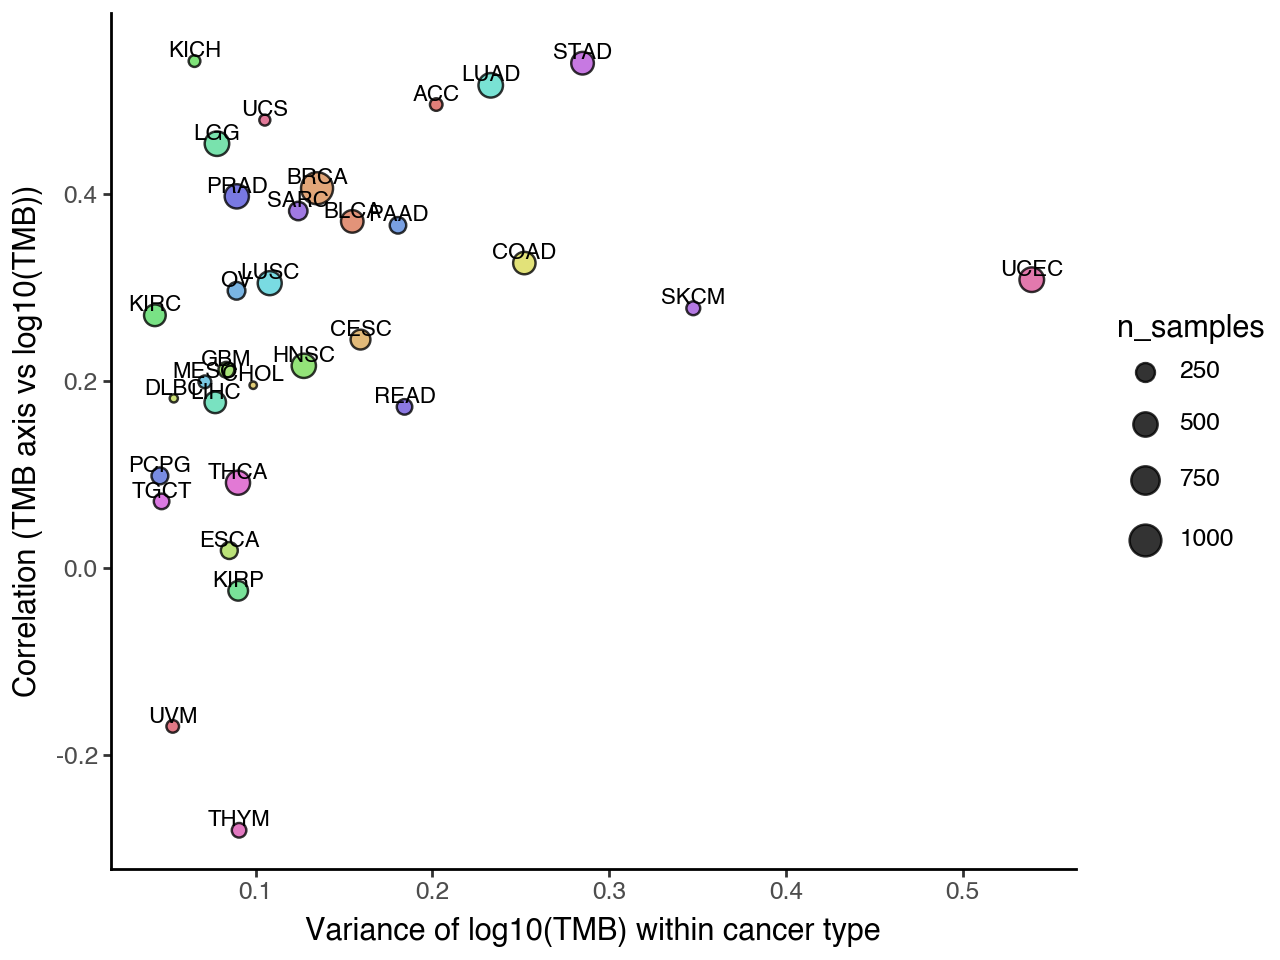

In [4]:
from plotnine import *

p = (
    ggplot(type_summary, aes(x='var_log_tmb', y='pearson_r_tmb_vs_tmb_axis'))
    + geom_point(
        aes(fill='cancer_type', size='n_samples'),
        alpha=0.8,
        stroke=0.5
    )
    + geom_text(
        aes(label='cancer_type'),
        nudge_y=0.01,   # small vertical shift so text isn't on top of points
        #nudge_x=0.02,
        size=8
    )
    #+ geom_smooth(method="lm", se=True, color="black")
    + guides(fill=False, color=False) # size=False
    + labs(
        x='Variance of log10(TMB) within cancer type',
        y='Correlation (TMB axis vs log10(TMB))',
        title=''
    )
    + theme_classic()
)
# p.save(f"{BASE_DIR}/results/figures/main/fig2/2b_var_tmb_vs_corr.pdf", dpi = 300)
p

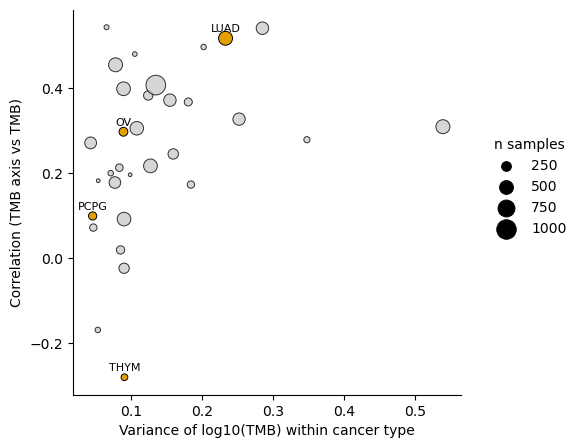

In [67]:
import sys, numpy as np
from matplotlib.ticker import MaxNLocator
sys.path.insert(0, f"{BASE_DIR}/local/figures")
from palette import COLORS

highlight_types = ["LUAD", "OV", "PCPG", "THYM"]

df = type_summary.copy()
df["highlight"] = df["cancer_type"].isin(highlight_types)
n_max = df["n_samples"].max()
s = df["n_samples"] / n_max * 200

fig, ax = plt.subplots(figsize=(5, 5))

ax.scatter(df.loc[~df["highlight"], "var_log_tmb"],
           df.loc[~df["highlight"], "pearson_r_tmb_vs_tmb_axis"],
           s=s[~df["highlight"]], color=COLORS["light_gray"],
           edgecolors="black", linewidths=0.7, alpha=0.8, zorder=1)
ax.scatter(df.loc[df["highlight"], "var_log_tmb"],
           df.loc[df["highlight"], "pearson_r_tmb_vs_tmb_axis"],
           s=s[df["highlight"]], color=COLORS["accent4"],
           edgecolors="black", linewidths=0.7, zorder=2)

for _, row in df[df["highlight"]].iterrows():
    ax.text(row["var_log_tmb"], row["pearson_r_tmb_vs_tmb_axis"] + 0.01,
            row["cancer_type"], fontsize=8, ha="center", va="bottom")

legend_ns = MaxNLocator(nbins=4, integer=True).tick_values(df["n_samples"].min(), n_max)
legend_ns = legend_ns[(legend_ns > 0) & (legend_ns <= n_max)].astype(int)
for n in legend_ns:
    ax.scatter([], [], s=n / n_max * 200,
               color=COLORS["black"], edgecolors="black", linewidths=0.7, label=n)
ax.legend(title="n samples", frameon=False, scatterpoints=1,
          bbox_to_anchor=(1.05, 0.7), loc="upper left")

ax.set_xlabel("Variance of log10(TMB) within cancer type")
ax.set_ylabel("Correlation (TMB axis vs TMB)")
ax.text(
    0.05,
    0.95,
    f"Spearman ρ = {rho_var:.2f}, p = {p_var:.3g} (var TMB)\n"
    f"Spearman ρ = {rho_n:.2f}, p = {p_n:.3g} (n samples)",
    transform=ax.transAxes,
    ha="left",
    va="top",
    fontsize=8,
)
ax.tick_params(colors="black")
sns.despine(ax=ax)
fig.savefig(f"{OUT_DIR}/2b_var_tmb_vs_corr_highlighted.pdf", dpi=300, bbox_inches="tight")
plt.show()

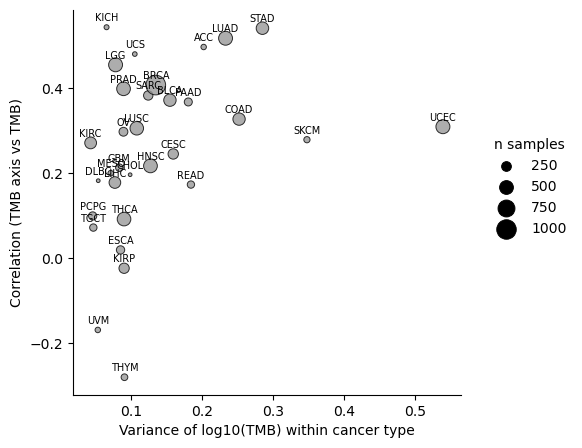

In [69]:
# Supplementary: all cancer types labeled, single color
n_max = type_summary["n_samples"].max()
s = type_summary["n_samples"] / n_max * 200

fig, ax = plt.subplots(figsize=(5, 5))

ax.scatter(type_summary["var_log_tmb"],
           type_summary["pearson_r_tmb_vs_tmb_axis"],
           s=s, color=COLORS["ns"], edgecolors="black", linewidths=0.7, alpha=0.8)

for _, row in type_summary.iterrows():
    ax.text(row["var_log_tmb"], row["pearson_r_tmb_vs_tmb_axis"] + 0.01,
            row["cancer_type"], fontsize=7, ha="center", va="bottom")

legend_ns = MaxNLocator(nbins=4, integer=True).tick_values(type_summary["n_samples"].min(), n_max)
legend_ns = legend_ns[(legend_ns > 0) & (legend_ns <= n_max)].astype(int)
for n in legend_ns:
    ax.scatter([], [], s=n / n_max * 200,
               color=COLORS["black"], edgecolors="black", linewidths=0.7, label=n)
ax.legend(title="n samples", frameon=False, scatterpoints=1,
          bbox_to_anchor=(1.05, 0.7), loc="upper left")

ax.set_xlabel("Variance of log10(TMB) within cancer type")
ax.set_ylabel("Correlation (TMB axis vs TMB)")
ax.tick_params(colors="black")
sns.despine(ax=ax)
fig.savefig(f"{OUT_DIR}/2b_var_tmb_vs_corr_supp.pdf", dpi=300, bbox_inches="tight")
plt.show()